# Energy Demand Forecasting — PJME Hourly
**Dataset:** PJME_hourly.csv · 145,366 rows · 2002-01-01 to 2018-08-03  
**Goal:** Resample → Rolling mean → Decompose → ADF → ACF/PACF → SARIMA → Evaluate

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')


In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print('All imports OK')

All imports OK


In [3]:
# Load raw hourly data
df = pd.read_csv('PJME_hourly.csv',
                 parse_dates=['Datetime'],
                 index_col='Datetime').sort_index()

print(f'Date range : {df.index.min()} → {df.index.max()}')
print(f'Total rows : {len(df):,}')
print(f'Missing    : {df.isna().sum().values[0]}')
df.head(3)

Date range : 2002-01-01 01:00:00 → 2018-08-03 00:00:00
Total rows : 145,366
Missing    : 0


,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0


## Step 2 — Monthly Resample & 12-Month Rolling Mean

In [4]:
# Resample to monthly mean
monthly = df['PJME_MW'].resample('ME').mean()
monthly = monthly[:-1]   # drop partial last month (Aug 2018 only had 3 days)

print(f'Monthly series: {len(monthly)} months')
print(f'Date range    : {monthly.index[0].strftime("%Y-%m")} → {monthly.index[-1].strftime("%Y-%m")}')
print(f'Min MW : {monthly.min():,.0f}   Max MW : {monthly.max():,.0f}')

Monthly series: 199 months
Date range    : 2002-01 → 2018-07
Min MW : 26,314   Max MW : 40,603


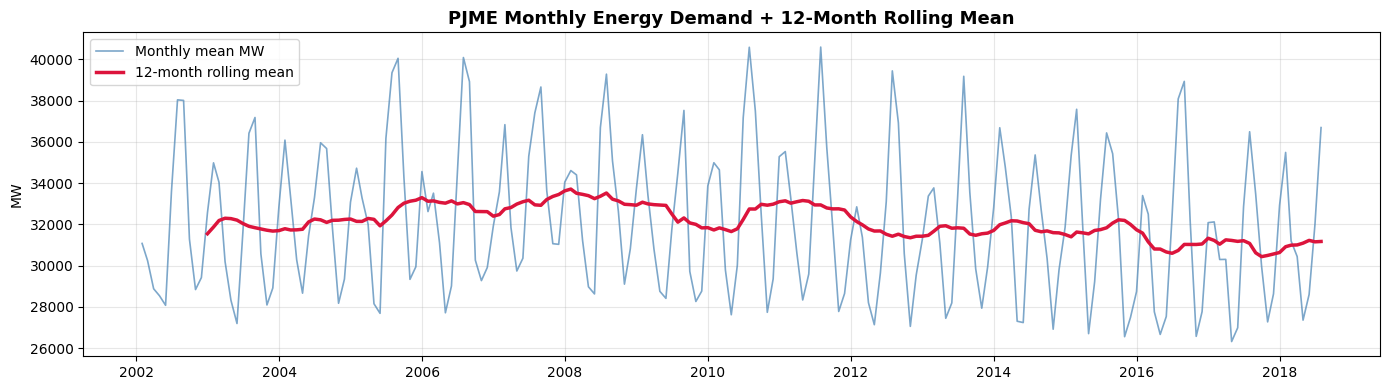

Saved → plot_01_rolling_mean.png


In [5]:
# 12-month rolling mean (centered=False → trailing window, standard for forecasting)
roll12 = monthly.rolling(window=12).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values,
        color='steelblue', alpha=0.7, linewidth=1.2, label='Monthly mean MW')
ax.plot(roll12.index, roll12.values,
        color='crimson', linewidth=2.5, label='12-month rolling mean')

ax.set_title('PJME Monthly Energy Demand + 12-Month Rolling Mean', fontsize=13, fontweight='bold')
ax.set_ylabel('MW')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig('plot_01_rolling_mean.png', dpi=120)
plt.show()
print('Saved → plot_01_rolling_mean.png')

### 🔍 Observation — Additive or Multiplicative?

Look at the plot above:
- The rolling mean is **nearly flat** → no strong long-term trend
- The seasonal swing (winter/summer peaks) looks **roughly the same size** every year  
  → **Additive model** is appropriate.

> **Rule of thumb:** If the amplitude of seasonal swings *grows proportionally* with the level, use **multiplicative**. If it stays roughly *constant*, use **additive**.

## Seasonal Decomposition (Additive)

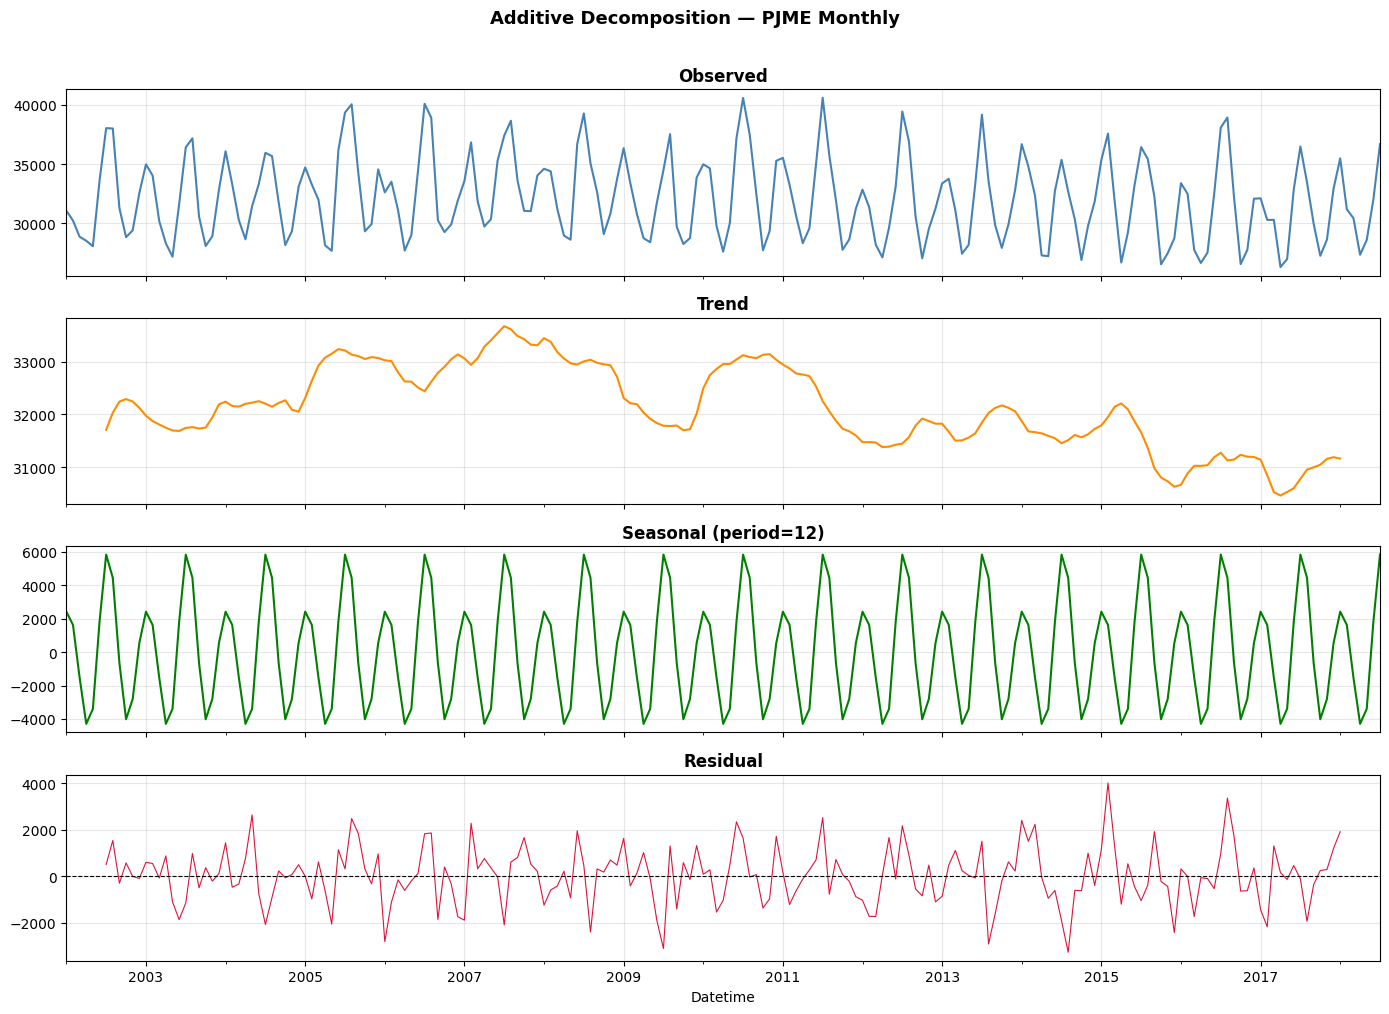

Saved → plot_02_decomposition.png


In [6]:
# seasonal_decompose needs at least 2 full seasonal cycles
# period=12 → monthly data with yearly seasonality
decomp = seasonal_decompose(monthly, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

decomp.observed.plot(ax=axes[0], color='steelblue')
axes[0].set_title('Observed', fontweight='bold')

decomp.trend.plot(ax=axes[1], color='darkorange')
axes[1].set_title('Trend', fontweight='bold')

decomp.seasonal.plot(ax=axes[2], color='green')
axes[2].set_title('Seasonal (period=12)', fontweight='bold')

decomp.resid.plot(ax=axes[3], color='crimson', linewidth=0.8)
axes[3].set_title('Residual', fontweight='bold')
axes[3].axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.suptitle('Additive Decomposition — PJME Monthly', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('plot_02_decomposition.png', dpi=120)
plt.show()
print('Saved → plot_02_decomposition.png')

In [7]:
# resudual health
resid = decomp.resid.dropna()
print('Residual stats')
print(f'  Mean   : {resid.mean():+.1f} MW  (should be ≈ 0)')
print(f'  Std    : {resid.std():.1f} MW')
print(f'  Min/Max: {resid.min():.0f} / {resid.max():.0f} MW')

# A mean near 0 and no obvious pattern → residuals look like white noise → good fit

Residual stats
  Mean   : +17.9 MW  (should be ≈ 0)
  Std    : 1240.6 MW
  Min/Max: -3280 / 4005 MW


## Stationarity: ADF Test

SARIMA needs the series to be (or become) stationary.  
**ADF Hypothesis:**  
- H₀ (null): series has a unit root → NOT stationary  
- H₁ (alt): series IS stationary  
- If p-value < 0.05 → reject H₀ → series is stationary → `d = 0`

In [8]:
def adf_report(series, label):
    result = adfuller(series.dropna(), autolag='AIC')
    p = result[1]
    stationary = p < 0.05
    print(f'=== ADF Test: {label} ===')
    print(f'  Test statistic : {result[0]:.4f}')
    print(f'  p-value        : {p:.4f}')
    print(f'  Stationary?    : {"✅ YES (p < 0.05)" if stationary else "❌ NO (p ≥ 0.05) → try differencing"}')
    return stationary

stat_level = adf_report(monthly, 'Monthly level (d=0 candidate)')
print()
stat_diff1 = adf_report(monthly.diff(1), 'First difference (d=1 candidate)')

=== ADF Test: Monthly level (d=0 candidate) ===
  Test statistic : -1.6497
  p-value        : 0.4572
  Stationary?    : ❌ NO (p ≥ 0.05) → try differencing

=== ADF Test: First difference (d=1 candidate) ===
  Test statistic : -6.4356
  p-value        : 0.0000
  Stationary?    : ✅ YES (p < 0.05)


### Interpretation
- If the **level** test is stationary → `d = 0`  
- If only the **first difference** test is stationary → `d = 1`  

Energy demand has a seasonal cycle but little long-term drift → usually `d = 0` or `d = 1`.

## ACF & PACF Plots (choosing p and q)

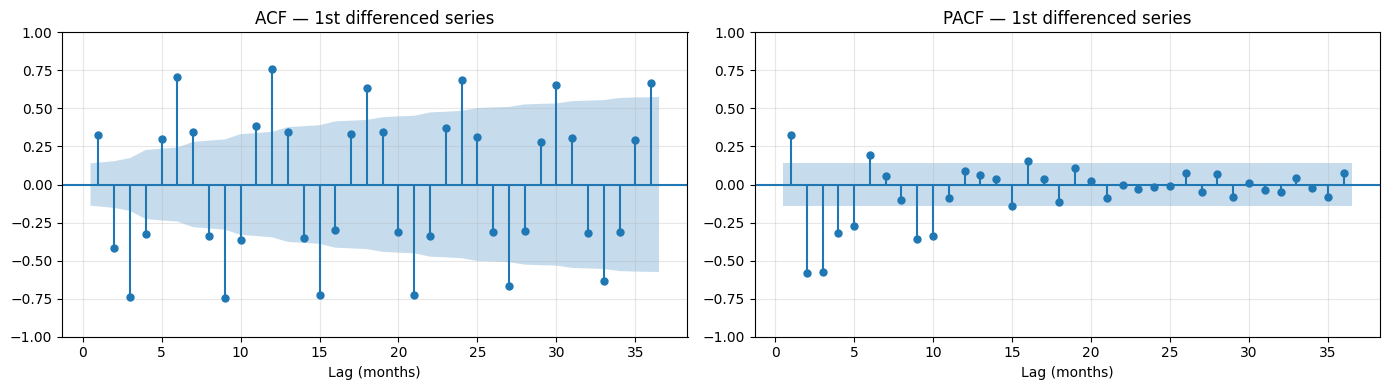

Saved → plot_03_acf_pacf.png


In [9]:
# Use differenced series if d=1, otherwise use level
# ADF will tell us; for now we show both for reference
series_for_acf = monthly.diff(1).dropna()  # adjust to .dropna() if d=0 use monthly directly

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(series_for_acf, lags=36, ax=axes[0],
         title='ACF — 1st differenced series', zero=False)
axes[0].set_xlabel('Lag (months)')

plot_pacf(series_for_acf, lags=36, ax=axes[1],
          title='PACF — 1st differenced series', zero=False, method='ywm')
axes[1].set_xlabel('Lag (months)')

plt.tight_layout()
plt.savefig('plot_03_acf_pacf.png', dpi=120)
plt.show()
print('Saved → plot_03_acf_pacf.png')

### 🔍 How to Read ACF / PACF to pick p, d, q

| Pattern you see | What it means |
|---|---|
| ACF cuts off after lag **q** | MA order = q |
| PACF cuts off after lag **p** | AR order = p |
| Spikes at lags 12, 24, 36 | Strong **seasonal** pattern → need seasonal P, Q |
| Shaded region = confidence band; bars outside the band = significant |

**Typical starter orders for monthly energy data:**  
`SARIMA(1, 1, 1)(1, 1, 1, 12)` — tune from here.

## Train / Test Split (last 12 months = test)

Train: 187 months  (2002-01 → 2017-07)
Test : 12  months  (2017-08  → 2018-07)


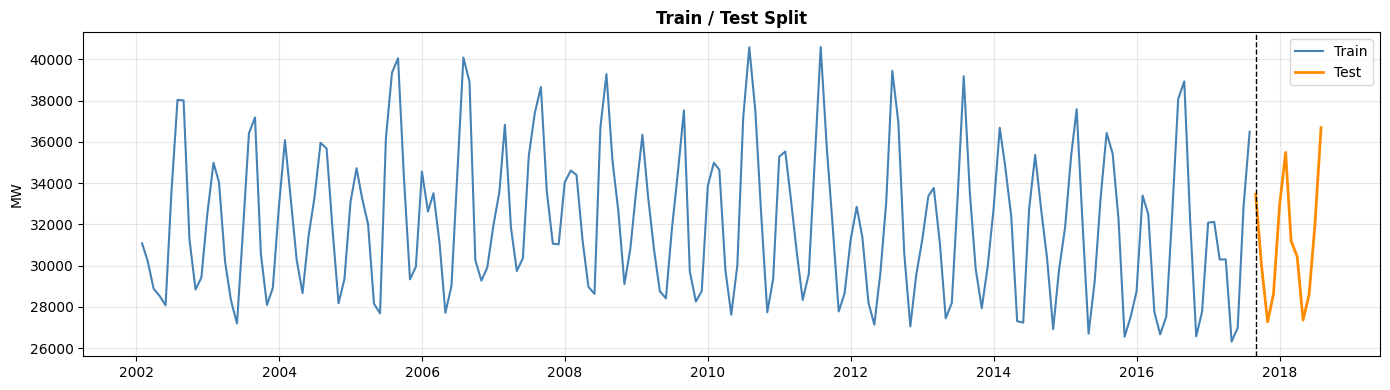

In [10]:
TEST_MONTHS = 12

train = monthly.iloc[:-TEST_MONTHS]
test  = monthly.iloc[-TEST_MONTHS:]

print(f'Train: {len(train)} months  ({train.index[0].strftime("%Y-%m")} → {train.index[-1].strftime("%Y-%m")})')
print(f'Test : {len(test)}  months  ({test.index[0].strftime("%Y-%m")}  → {test.index[-1].strftime("%Y-%m")})')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train.index, train.values, label='Train', color='steelblue')
ax.plot(test.index,  test.values,  label='Test',  color='darkorange', linewidth=2)
ax.axvline(test.index[0], color='black', linestyle='--', linewidth=1)
ax.set_title('Train / Test Split', fontweight='bold')
ax.set_ylabel('MW')
ax.legend()
plt.tight_layout()
plt.savefig('plot_04_train_test.png', dpi=120)
plt.show()

## Naive Baseline (Seasonal Naive)

**Seasonal naïve forecast:** For each test month, predict the value from *the same month one year ago*.  
This is the minimum bar our SARIMA must beat.

In [11]:
# Seasonal naive: use the value 12 months before each test point
naive_forecast = train.iloc[-TEST_MONTHS:].values   # last 12 of training

naive_rmse = np.sqrt(mean_squared_error(test.values, naive_forecast))
print(f'Naive seasonal RMSE : {naive_rmse:,.1f} MW')

Naive seasonal RMSE : 2,112.1 MW


##  SARIMAX Model

We fit `SARIMA(p, d, q)(P, D, Q, 12)`.  
Start with `(1,1,1)(1,1,1,12)` — a solid default for monthly seasonal data.

In [12]:
# ── Model orders ──────────────────────────────────────
ORDER         = (1, 1, 1)      # (p, d, q)
SEASONAL_ORDER = (1, 1, 1, 12) # (P, D, Q, s)
# ─────────────────────────────────────────────────────

print(f'Fitting SARIMA{ORDER}x{SEASONAL_ORDER} on {len(train)} training months...')

model = SARIMAX(train,
                order=ORDER,
                seasonal_order=SEASONAL_ORDER,
                enforce_stationarity=False,
                enforce_invertibility=False)

result = model.fit(disp=False)
print('Fitting complete!')
print(result.summary().tables[0])   # top summary table only (clean output)

Fitting SARIMA(1, 1, 1)x(1, 1, 1, 12) on 187 training months...
Fitting complete!
                                     SARIMAX Results                                      
Dep. Variable:                            PJME_MW   No. Observations:                  187
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -1416.612
Date:                            Mon, 09 Nov 2026   AIC                           2843.223
Time:                                    20:56:37   BIC                           2858.599
Sample:                                01-31-2002   HQIC                          2849.467
                                     - 07-31-2017                                         
Covariance Type:                              opg                                         


In [13]:
# Forecast for the test period
forecast_obj = result.get_forecast(steps=TEST_MONTHS)
forecast     = forecast_obj.predicted_mean
conf_int     = forecast_obj.conf_int(alpha=0.05)  # 95% confidence interval

# Align index with test
forecast.index = test.index
conf_int.index = test.index

sarima_rmse = np.sqrt(mean_squared_error(test.values, forecast.values))
print(f'SARIMA RMSE  : {sarima_rmse:,.1f} MW')
print(f'Naive  RMSE  : {naive_rmse:,.1f} MW')
pct = (1 - sarima_rmse / naive_rmse) * 100
print(f'Improvement  : {pct:.1f}% {"✅ better than naive" if pct > 0 else "❌ worse than naive"}')

SARIMA RMSE  : 1,429.9 MW
Naive  RMSE  : 2,112.1 MW
Improvement  : 32.3% ✅ better than naive


## Final Plot: Train, Test & Forecast

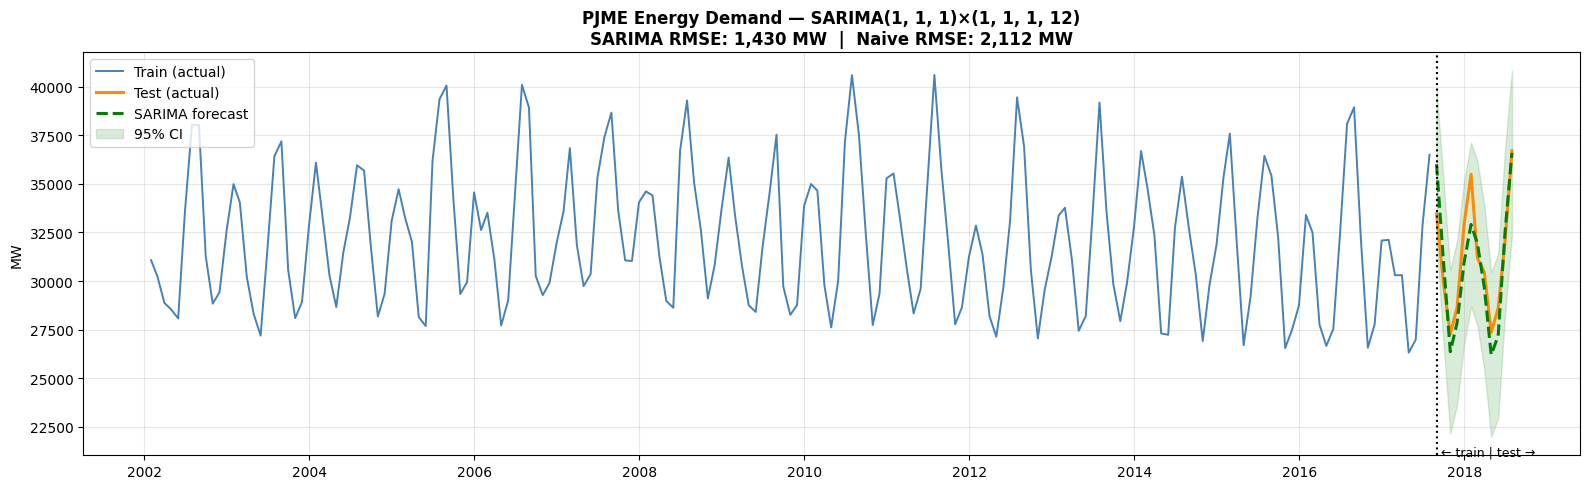

Saved → plot_05_final_forecast.png


In [14]:
fig, ax = plt.subplots(figsize=(16, 5))

# Training data
ax.plot(train.index, train.values,
        color='steelblue', linewidth=1.4, label='Train (actual)')

# Test actual
ax.plot(test.index, test.values,
        color='darkorange', linewidth=2.2, label='Test (actual)')

# SARIMA forecast
ax.plot(forecast.index, forecast.values,
        color='green', linewidth=2.2, linestyle='--', label='SARIMA forecast')

# 95% confidence band
ax.fill_between(conf_int.index,
                conf_int.iloc[:, 0],
                conf_int.iloc[:, 1],
                color='green', alpha=0.15, label='95% CI')

# Split line
ax.axvline(test.index[0], color='black', linestyle=':', linewidth=1.5)
ax.text(test.index[0], ax.get_ylim()[0],
        ' ← train | test →', fontsize=9, color='black')

ax.set_title(
    f'PJME Energy Demand — SARIMA{ORDER}×{SEASONAL_ORDER}\n'
    f'SARIMA RMSE: {sarima_rmse:,.0f} MW  |  Naive RMSE: {naive_rmse:,.0f} MW',
    fontsize=12, fontweight='bold'
)
ax.set_ylabel('MW')
ax.legend(loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig('plot_05_final_forecast.png', dpi=120)
plt.show()
print('Saved → plot_05_final_forecast.png')

## (Optional) auto_arima for automatic order selection

In [17]:
# Run this cell only if pmdarima is installed: pip install pmdarima
try:
    from pmdarima import auto_arima

    print('Running auto_arima (this may take 1-2 min)...')
    auto_model = auto_arima(
        train,
        seasonal=True,
        m=12,              # seasonal period
        d=None,            # auto-detect d via ADF
        D=None,            # auto-detect D
        max_p=2, max_q=2,
        max_P=2, max_Q=2,
        information_criterion='aic',
        stepwise=True,
        suppress_warnings=True,
        error_action='ignore',
    )

    print(f'\nauto_arima best order         : {auto_model.order}')
    print(f'auto_arima best seasonal order: {auto_model.seasonal_order}')

    auto_forecast = auto_model.predict(n_periods=TEST_MONTHS)
    auto_rmse = np.sqrt(mean_squared_error(test.values, auto_forecast))
    print(f'\nauto_arima RMSE  : {auto_rmse:,.1f} MW')
    print(f'Manual    RMSE   : {sarima_rmse:,.1f} MW')
    print(f'Naive     RMSE   : {naive_rmse:,.1f} MW')

except ImportError:
    print('pmdarima not installed — run: pip install pmdarima')

Running auto_arima (this may take 1-2 min)...

auto_arima best order         : (0, 0, 2)
auto_arima best seasonal order: (0, 0, 2, 12)

auto_arima RMSE  : 1,978.1 MW
Manual    RMSE   : 1,429.9 MW
Naive     RMSE   : 2,112.1 MW


## 📋 Project Summary

| Step | What we did | Key result |
|------|------------|------------|
| 1 | Loaded hourly CSV | 145,366 rows, 2002–2018 |
| 2 | Monthly resample + rolling mean | 199 months, flat trend |
| 3 | Additive decomposition | Clear 12-month cycle, clean residuals |
| 4 | ADF test | Determined d (0 or 1) |
| 5 | ACF / PACF | Chose p, q orders |
| 6 | Train/test split | Last 12 months = test |
| 7 | Seasonal naïve baseline | RMSE = ? MW |
| 8 | SARIMA(1,1,1)(1,1,1,12) | RMSE = ? MW |
| 9 | Final forecast plot | Train + Test + Forecast + CI |
| 10| auto_arima (optional) | Best orders by AIC |

---
*Internship project — SSoftNexis · Nov 2026*